In [202]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# **Load and Inspect Data**

In [203]:
df=pd.read_csv('Car_details_v3.csv')
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [204]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 825.6 KB


In [205]:
df.shape

(8128, 13)

In [169]:
df.describe()

,year,selling_price,km_driven,seats
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,5.416719
std,4.044249,8.062534e+05,5.655055e+04,0.959588
min,1983.000000,2.999900e+04,1.000000e+00,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,5.000000
75%,2017.000000,6.750000e+05,9.800000e+04,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000


In [206]:
df.isna().sum()

name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           222
seats            221
dtype: int64

In [207]:
# Check Duplicates
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
8123    False
8124    False
8125    False
8126     True
8127     True
Length: 8128, dtype: bool

In [208]:
# Remove Duplicates
df=df.drop_duplicates()
df.shape

(6926, 13)

In [210]:
# Check Columns
cols=df.columns
cols

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque',
       'seats'],
      dtype='str')

In [211]:
# take numerical columns
num_cols=df.select_dtypes(include=[np.number]).columns.to_list()
num_cols

['year', 'selling_price', 'km_driven', 'seats']

In [212]:
df.info()

<class 'pandas.DataFrame'>
Index: 6926 entries, 0 to 8125
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           6926 non-null   str    
 1   year           6926 non-null   int64  
 2   selling_price  6926 non-null   int64  
 3   km_driven      6926 non-null   int64  
 4   fuel           6926 non-null   str    
 5   seller_type    6926 non-null   str    
 6   transmission   6926 non-null   str    
 7   owner          6926 non-null   str    
 8   mileage        6718 non-null   str    
 9   engine         6718 non-null   str    
 10  max_power      6721 non-null   str    
 11  torque         6717 non-null   str    
 12  seats          6718 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 757.5 KB


In [213]:
str_cols = df.select_dtypes(include=['object', 'string']).columns
str_cols

Index(['name', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage',
       'engine', 'max_power', 'torque'],
      dtype='str')

In [224]:
df['name'].value_counts(dropna=False)

name
Maruti Swift Dzire VDI                          118
Maruti Alto 800 LXI                              76
Maruti Alto LXi                                  69
Maruti Swift VDI                                 60
Maruti Swift VDI BSIV                            56
                                               ... 
Maruti Celerio ZXI AMT BSIV                       1
Tata Bolt Revotron XM                             1
Tata Manza Aura (ABS) Safire BS IV                1
Tata Nexon 1.5 Revotorq XT                        1
Toyota Innova 2.5 GX (Diesel) 8 Seater BS IV      1
Name: count, Length: 2058, dtype: int64

In [225]:
df['fuel'].value_counts(dropna=False)

fuel
Diesel    3755
Petrol    3077
CNG         56
LPG         38
Name: count, dtype: int64

In [226]:
df['seller_type'].value_counts(dropna=False)

seller_type
Individual          6218
Dealer               681
Trustmark Dealer      27
Name: count, dtype: int64

In [227]:
df['transmission'].value_counts(dropna=False)

transmission
Manual       6342
Automatic     584
Name: count, dtype: int64

In [228]:
df['owner'].value_counts(dropna=False)

owner
First Owner             4242
Second Owner            1974
Third Owner              536
Fourth & Above Owner     169
Test Drive Car             5
Name: count, dtype: int64

In [229]:
df['mileage'].value_counts(dropna=False)

mileage
18.9 kmpl     210
NaN           208
19.7 kmpl     168
18.6 kmpl     150
21.1 kmpl     146
             ... 
11.3 kmpl       1
15.1 km/kg      1
14.21 kmpl      1
11.72 kmpl      1
16.51 kmpl      1
Name: count, Length: 394, dtype: int64

In [230]:
df[['fuel','mileage']].value_counts(dropna=False)

fuel    mileage   
Petrol  18.9 kmpl     210
        19.7 kmpl     164
        18.6 kmpl     147
        21.1 kmpl     118
Diesel  15.96 kmpl    108
                     ... 
CNG     15.1 km/kg      1
Diesel  14.21 kmpl      1
Petrol  21.7 kmpl       1
Diesel  11.72 kmpl      1
Petrol  16.51 kmpl      1
Name: count, Length: 486, dtype: int64

In [231]:
df['engine'].value_counts(dropna=False)

engine
1248 CC    907
1197 CC    698
796 CC     421
998 CC     398
2179 CC    339
          ... 
2650 CC      1
2446 CC      1
3498 CC      1
2776 CC      1
1950 CC      1
Name: count, Length: 122, dtype: int64

In [232]:
df['max_power'].value_counts(dropna=False)

max_power
74 bhp       324
NaN          205
88.5 bhp     177
46.3 bhp     158
67 bhp       152
            ... 
194 bhp        1
60.2 bhp       1
134 bhp        1
203 bhp        1
135.1 bhp      1
Name: count, Length: 323, dtype: int64

In [233]:
df['torque'].value_counts(dropna=False)

torque
190Nm@ 2000rpm            472
200Nm@ 1750rpm            398
90Nm@ 3500rpm             353
NaN                       209
62Nm@ 3000rpm             160
                         ... 
250.06nm@ 1500-2750rpm      1
90nm@ 3500rpm               1
190Nm@ 3700rpm              1
436.4Nm@ 1800-2500rpm       1
96  Nm at 3000  rpm         1
Name: count, Length: 442, dtype: int64

# **EDA**

                Target  Skewness
   selling_price (raw)      5.57
log(1 + selling_price)     -0.16


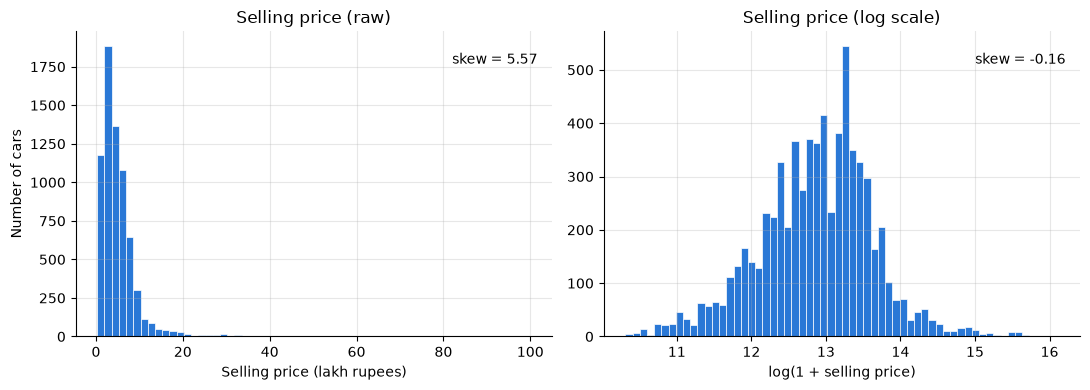

In [234]:
# Price distribution
df["log_price"] = np.log1p(df["selling_price"])

# Skewness values (these go in your caption and table)
skew_raw = df["selling_price"].skew()
skew_log = df["log_price"].skew()
print(pd.DataFrame({
    "Target": ["selling_price (raw)", "log(1 + selling_price)"],
    "Skewness": [round(skew_raw, 2), round(skew_log, 2)],
}).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(df["selling_price"] / 1e5, bins=60, color="#2a78d6", edgecolor="white", linewidth=0.5)
axes[0].set_title("Selling price (raw)")
axes[0].set_xlabel("Selling price (lakh rupees)")
axes[0].set_ylabel("Number of cars")
axes[0].text(0.97, 0.93, f"skew = {skew_raw:.2f}", transform=axes[0].transAxes, ha="right", va="top")

axes[1].hist(df["log_price"], bins=60, color="#2a78d6", edgecolor="white", linewidth=0.5)
axes[1].set_title("Selling price (log scale)")
axes[1].set_xlabel("log(1 + selling price)")
axes[0].set_ylabel("Number of cars")
axes[1].text(0.97, 0.93, f"skew = {skew_log:.2f}", transform=axes[1].transAxes, ha="right", va="top")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


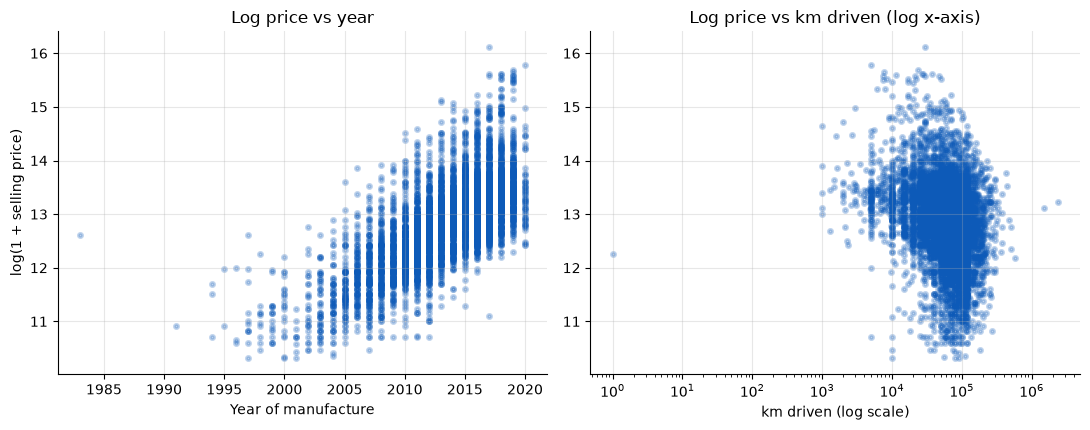

In [235]:
# Price vs year and km driven
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))

axes[0].scatter(df["year"], df["log_price"], s=9, alpha=0.25, color="#0d5ab8", linewidths=2)
axes[0].set_title("Log price vs year")
axes[0].set_xlabel("Year of manufacture")
axes[0].set_ylabel("log(1 + selling price)")

axes[1].scatter(df["km_driven"].clip(lower=1), df["log_price"], s=9, alpha=0.25, color="#0d5ab8", linewidths=2)
axes[1].set_xscale("log")
axes[1].set_title("Log price vs km driven (log x-axis)")
axes[1].set_xlabel("km driven (log scale)")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

          median     n
fuel                  
CNG     320000.0    56
Diesel  520000.0  3755
LPG     195500.0    38
Petrol  310000.0  3077 

                median     n
transmission                
Automatic     850000.0   584
Manual        385000.0  6342 



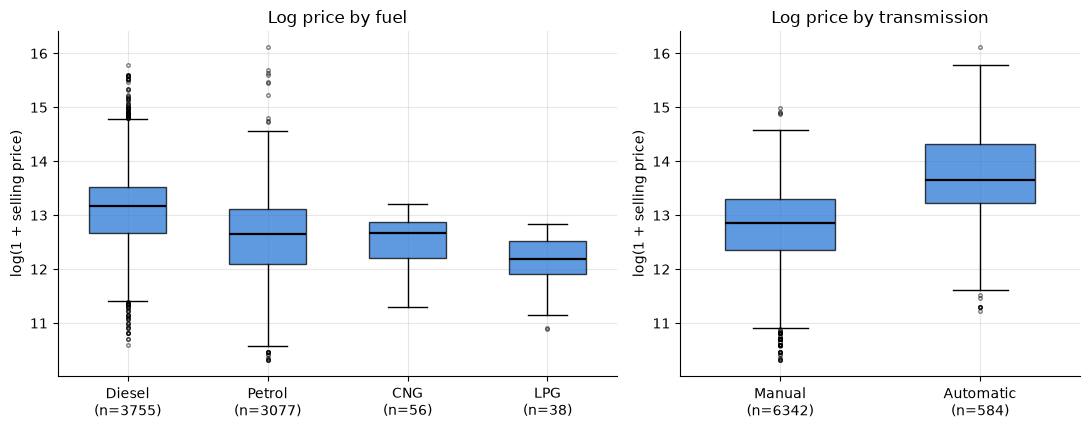

In [236]:
# Price by fuel and transmission
for col in ["fuel", "transmission"]:
    print(df.groupby(col)["selling_price"].agg(median="median", n="count"), "\n")

def box_by(ax, col, order):
    data = [df.loc[df[col] == k, "log_price"].values for k in order]
    bp = ax.boxplot(data, patch_artist=True, widths=0.55,
                    medianprops=dict(color="black", linewidth=1.6),
                    flierprops=dict(marker="o", markersize=2.5, alpha=0.5))
    for box in bp["boxes"]:
        box.set_facecolor("#2a78d6"); box.set_alpha(0.75)
    ax.set_xticks(range(1, len(order) + 1))
    ax.set_xticklabels([f"{k}\n(n={len(d)})" for k, d in zip(order, data)])
    ax.set_ylabel("log(1 + selling price)")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1.4, 1]})
box_by(axes[0], "fuel", ["Diesel", "Petrol", "CNG", "LPG"]);  axes[0].set_title("Log price by fuel")
box_by(axes[1], "transmission", ["Manual", "Automatic"]);     axes[1].set_title("Log price by transmission")

plt.tight_layout()
plt.show()

In [240]:
# Outlier
# Counts for the table
q1, q3 = df["km_driven"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print("IQR upper fence (km):", upper)
print("km_driven above fence:", (df["km_driven"] > upper).sum())
print("km_driven > 300,000:", (df["km_driven"] > 300_000).sum())
print("km_driven > 500,000:", (df["km_driven"] > 500_000).sum())
print("km_driven <= 1:", (df["km_driven"] <= 1).sum())
print("year < 2000:", (df["year"] < 2000).sum())
print("price > 50 lakh:", (df["selling_price"] > 5_000_000).sum())

# Inspect the extremes before deciding
print(df.sort_values("km_driven", ascending=False).head(10)[["name", "year", "km_driven", "selling_price"]])

IQR upper fence (km): 190000.0
km_driven above fence: 167
km_driven > 300,000: 18
km_driven > 500,000: 3
km_driven <= 1: 1
year < 2000: 48
price > 50 lakh: 20
                                               name  year  km_driven  \
3486                           Hyundai i20 Asta 1.2  2007    2360457   
1810                         Mahindra XUV500 W6 2WD  2012    1500000   
3508                       Maruti Wagon R LXI Minor  2010     577414   
6673  Toyota Innova 2.5 EV Diesel PS 7 Seater BSIII  2011     500000   
3641                       Maruti Wagon R VXI BS IV  2011     500000   
5106                          Mahindra Scorpio M2DI  2011     475000   
5189         Toyota Innova 2.5 VX (Diesel) 7 Seater  2013     440000   
5467   Toyota Innova 2.5 VX (Diesel) 7 Seater BS IV  2010     426000   
2272                            Mahindra Bolero SLE  2010     380000   
7102            Toyota Innova 2.5 V Diesel 8-seater  2007     376412   

      selling_price  
3486         550000  
1810

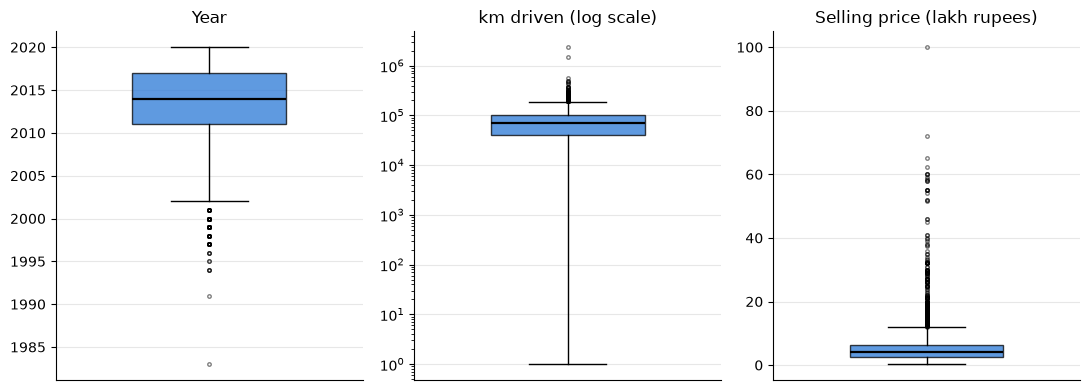

In [239]:
# Boxplots
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
panels = [("Year", df["year"]),
          ("km driven (log scale)", df["km_driven"].clip(lower=1)),
          ("Selling price (lakh rupees)", df["selling_price"] / 1e5)]
for ax, (title, values) in zip(axes, panels):
    bp = ax.boxplot(values, patch_artist=True, widths=0.5,
                    medianprops=dict(color="black", linewidth=1.6),
                    flierprops=dict(marker="o", markersize=2.5, alpha=0.5))
    bp["boxes"][0].set_facecolor("#2a78d6"); bp["boxes"][0].set_alpha(0.75)
    ax.set_title(title); ax.set_xticks([])
    ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
axes[1].set_yscale("log")

plt.tight_layout()
plt.show()


# **Data Cleaning**

In [188]:
# Change Mileaga
df['mileage_num'] = df['mileage'].str.extract(r'([\d.]+)')[0].astype(float)
mask = df['mileage'].str.contains('km/kg', na=False)  
df.loc[mask, 'mileage_num'] = df.loc[mask, 'mileage_num'] / 1.47
df['mileage'] = df['mileage_num'].round(2)
df = df.drop(columns='mileage_num')
df['mileage'].value_counts(dropna=False)

mileage
18.90    210
NaN      208
19.70    168
18.60    150
21.10    146
        ... 
11.30      1
10.27      1
14.21      1
11.72      1
16.51      1
Name: count, Length: 391, dtype: int64

In [189]:
df[['fuel','mileage']].value_counts(dropna=False)

fuel    mileage
Petrol  18.90      210
        19.70      164
        18.60      147
        21.10      118
Diesel  15.96      108
                  ... 
CNG     10.27        1
Diesel  14.21        1
Petrol  21.70        1
Diesel  11.72        1
Petrol  16.51        1
Name: count, Length: 486, dtype: int64

In [190]:
# NaN mileage per fuel type
df[df['mileage'].isna()]['fuel'].value_counts()

fuel
Petrol    104
Diesel     97
CNG         4
LPG         3
Name: count, dtype: int64

In [191]:
# Zero mileage per fuel type
df[df['mileage'] == 0]['fuel'].value_counts()

fuel
Petrol    10
Diesel     5
Name: count, dtype: int64

In [192]:
# Convert 0 and NaN value with median
df['mileage'] = df['mileage'].replace(0, np.nan)
df['mileage'] = df['mileage'].fillna(df.groupby('fuel')['mileage'].transform('median'))
df['mileage'].isna().sum()

np.int64(0)

In [193]:
# sey engine float into engine_cc
df['engine_cc'] = df['engine'].str.extract(r'([\d.]+)')[0].astype(float)

In [194]:
# Check 'engine' NaN value
df['engine_cc'].isna().sum()

np.int64(208)

In [195]:
# Check 'engine' 0 value
(df['engine_cc'] == 0).sum()

np.int64(0)

In [196]:
# convert nan value with median
df['engine_cc'] = df['engine_cc'].fillna(df.groupby('name')['engine_cc'].transform('median'))
# 2. median of the same brand + fuel
df['engine_cc'] = df['engine_cc'].fillna(df.groupby('fuel')['engine_cc'].transform('median'))
# check
df['engine_cc'].isna().sum()

np.int64(0)

In [197]:
# Check max power and replace nan
df['max_power_bhp'] = df['max_power'].str.extract(r'([\d.]+)')[0].astype(float)
df['max_power_bhp'].isna().sum()

np.int64(206)

In [198]:
# Check 'max_power' 0 value
(df['max_power_bhp'] == 0).sum()

np.int64(3)

In [199]:
df['max_power_bhp'] = df['max_power_bhp'].replace(0, np.nan)
df['max_power_bhp'] = df['max_power_bhp'].fillna(df.groupby('name')['max_power_bhp'].transform('median'))
df['max_power_bhp'] = df['max_power_bhp'].fillna(df.groupby(['fuel', 'engine_cc'])['max_power_bhp'].transform('median'))
df['max_power_bhp'] = df['max_power_bhp'].fillna(df.groupby('fuel')['max_power_bhp'].transform('median'))

In [200]:
df['max_power_bhp'].isna().sum()

np.int64(0)

In [201]:
# Check 'max_power' 0 value
(df['max_power_bhp'] == 0).sum()

np.int64(0)